# Task 1.2: SAM Guided Prompts Refinement & MMSegmentation Structuring


This sprint extends the Sprint-2 auto-labeling prototype with two goals:

1. Reduce mask fragmentation using guided prompts (points / bounding boxes) with `SamPredictor`, instead of the fully-automatic grid-only mode.
2. Structure the official MMSegmentation directory hierarchy (`images/training`, `images/validation`, `annotations/training`, `annotations/validation`) on Google Drive.


## 1. Environment setup

In [1]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git
!pip install -q opencv-python-headless matplotlib numpy torch torchvision ipywidgets scikit-learn

import os, glob, cv2, shutil, random
import numpy as np
import torch
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Torch:", torch.__version__, "| Device:", DEVICE)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 110.6 MB/s eta 0:00:00
Torch: 2.11.0+cu128 | Device: cuda


## 2. Load SAM checkpoint

In [2]:
import urllib.request

MODEL_TYPE = "vit_b"
CHECKPOINTS = {
    "vit_b": ("sam_vit_b_01ec64.pth", "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"),
    "vit_h": ("sam_vit_h_4b8939.pth", "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth"),
}
ckpt_name, ckpt_url = CHECKPOINTS[MODEL_TYPE]
if not os.path.exists(ckpt_name):
    print(f"Downloading {ckpt_name} ...")
    urllib.request.urlretrieve(ckpt_url, ckpt_name)
print("Checkpoint ready:", ckpt_name)


Checkpoint ready: sam_vit_b_01ec64.pth


In [3]:
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator

sam = sam_model_registry[MODEL_TYPE](checkpoint=ckpt_name)
sam.to(device=DEVICE)
predictor = SamPredictor(sam)
print("SAM loaded and SamPredictor ready.")

SAM loaded and SamPredictor ready.


## 3. Mount Drive and locate CLAHE frames


In [4]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT     = "/content/drive/MyDrive/Under_Water_Dataset"
PROCESSED_DIR  = os.path.join(DRIVE_ROOT, "Dataset_Processed")
FILTER_FOLDER  = "Frames_CLAHE"
IMAGE_DIR      = os.path.join(PROCESSED_DIR, FILTER_FOLDER)

exts = ("*.jpg", "*.jpeg", "*.png")
image_paths = sorted(
    p for e in exts for p in glob.glob(os.path.join(IMAGE_DIR, e))
    if "mask" not in os.path.basename(p).lower()
)
print(f"{len(image_paths)} CLAHE frames found in {FILTER_FOLDER}.")

Mounted at /content/drive
105 CLAHE frames found in Frames_CLAHE.


## 4. Guided-prompt segmentation

`SamPredictor` accepts **point** and **box** prompts. Instead of SAM guessing every object in a grid, so it returns a single coherent pipe mask instead of dozens of fragments.

- **Point prompts**: foreground points on the pipe (label 1) and optional background points (label 0).
- **Box prompt**: a bounding box around the pipe.


In [5]:
def segment_with_points(image_rgb, fg_points, bg_points=None):
    """Segment using foreground/background point prompts.
    fg_points, bg_points: list of (x, y) pixel coordinates.
    Returns a binary uint8 mask (0/255)."""
    predictor.set_image(image_rgb)
    pts = list(fg_points) + (list(bg_points) if bg_points else [])
    labels = [1] * len(fg_points) + ([0] * len(bg_points) if bg_points else [])
    masks, scores, _ = predictor.predict(
        point_coords=np.array(pts),
        point_labels=np.array(labels),
        multimask_output=True,
    )
    best = masks[np.argmax(scores)]
    return (best.astype(np.uint8) * 255), float(scores.max())

def segment_with_box(image_rgb, box_xyxy):
    """Segment using a bounding box prompt [x0, y0, x1, y1]."""
    predictor.set_image(image_rgb)
    masks, scores, _ = predictor.predict(
        box=np.array(box_xyxy)[None, :],
        multimask_output=True,
    )
    best = masks[np.argmax(scores)]
    return (best.astype(np.uint8) * 255), float(scores.max())

def load_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

### 4.1 Demo

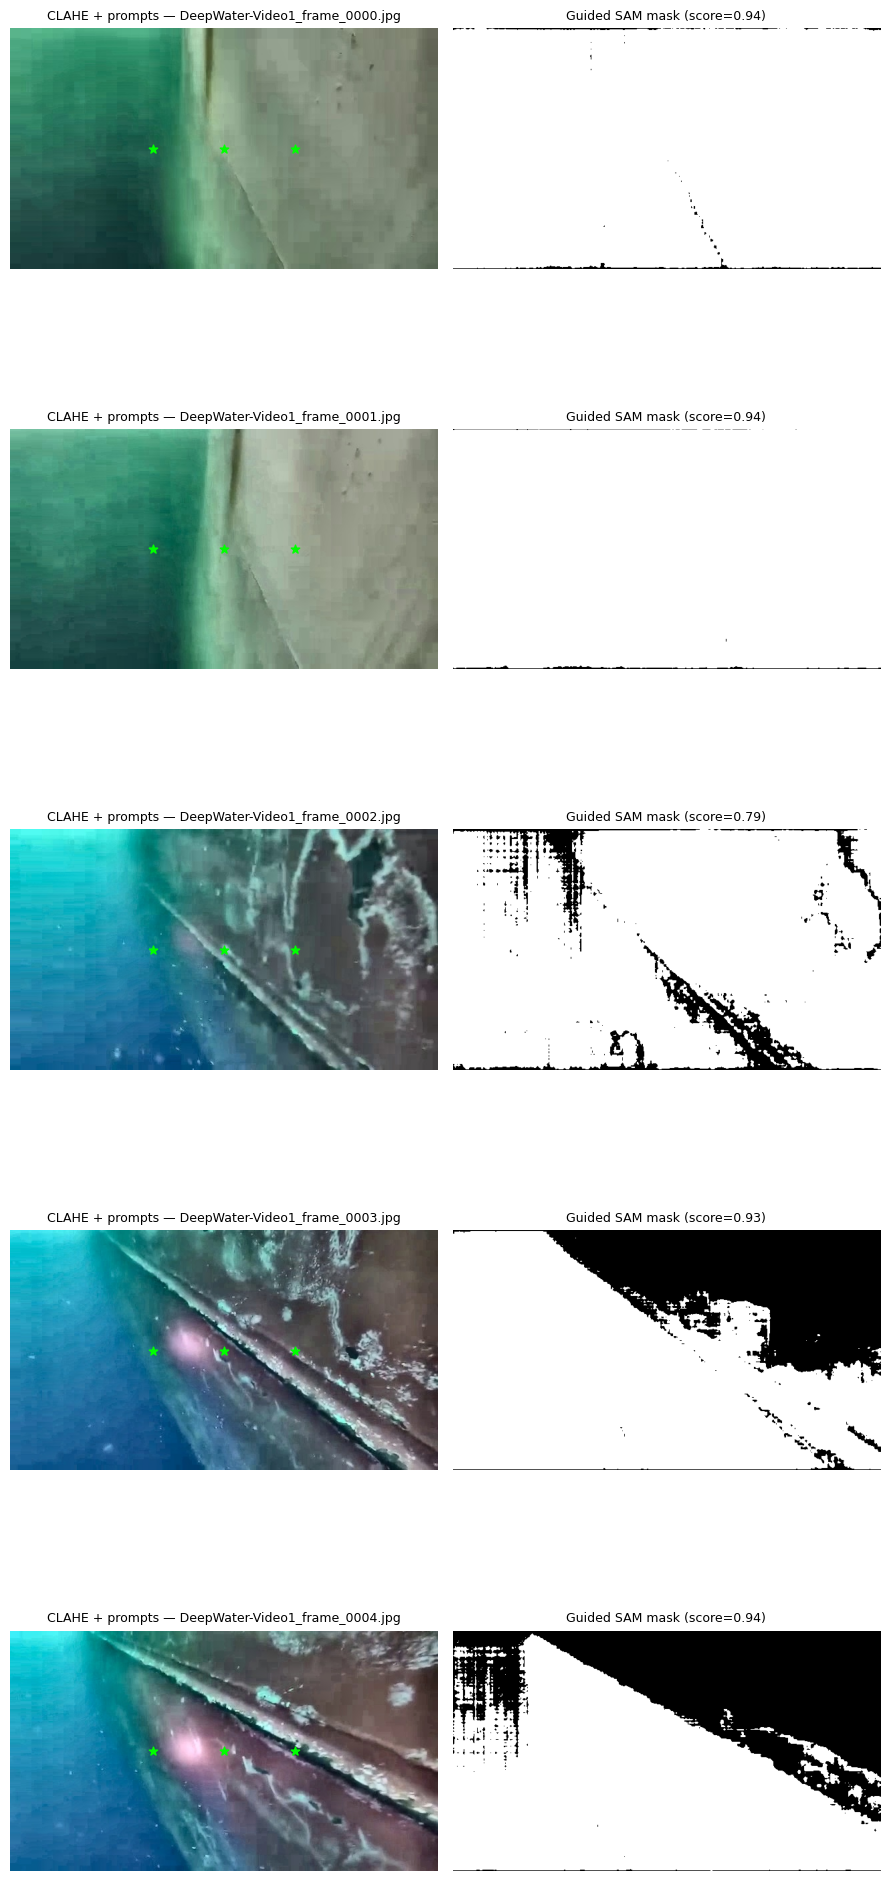

In [6]:
def demo_center_prompt(n_show=5):
    subset = image_paths[:n_show]
    if not subset:
        print("No images found."); return
    fig, axes = plt.subplots(len(subset), 2, figsize=(9, 4.2*len(subset)))
    if len(subset) == 1: axes = axes.reshape(1, 2)
    for i, path in enumerate(subset):
        img = load_rgb(path)
        h, w = img.shape[:2]

        fg = [(w//2, h//2), (w//3, h//2), (2*w//3, h//2)]
        mask, score = segment_with_points(img, fg)
        axes[i,0].imshow(img); axes[i,0].scatter(*zip(*fg), c="lime", s=40, marker="*")
        axes[i,0].set_title(f"CLAHE + prompts — {os.path.basename(path)}", fontsize=9); axes[i,0].axis("off")
        axes[i,1].imshow(mask, cmap="gray")
        axes[i,1].set_title(f"Guided SAM mask (score={score:.2f})", fontsize=9); axes[i,1].axis("off")
    plt.tight_layout(); plt.show()

demo_center_prompt(5)

### 4.2 Compare automatic vs. guided

We quantify fragmentation as the number of connected components in the mask.

In [7]:
from scipy import ndimage

auto_gen = SamAutomaticMaskGenerator(model=sam, points_per_side=32)

def n_components(binary_mask):
    _, n = ndimage.label(binary_mask > 127)
    return n

def fragmentation_report(n_show=5):
    rows = []
    for path in image_paths[:n_show]:
        img = load_rgb(path)
        # automatic union mask
        auto = np.zeros(img.shape[:2], np.uint8)
        for m in auto_gen.generate(img):
            auto[m["segmentation"]] = 255
        # guided
        h, w = img.shape[:2]
        guided, _ = segment_with_points(img, [(w//2, h//2), (w//3, h//2), (2*w//3, h//2)])
        rows.append((os.path.basename(path), n_components(auto), n_components(guided)))
    print(f"{'Frame':<32} | {'Auto #comp':>10} | {'Guided #comp':>12}")
    print("-"*60)
    for name, a, g in rows:
        print(f"{name:<32} | {a:>10} | {g:>12}")
    print("\n→ Lower guided component count = less fragmentation (goal of Task 1.2).")

fragmentation_report(5)

Frame                            | Auto #comp | Guided #comp
------------------------------------------------------------
DeepWater-Video1_frame_0000.jpg  |          9 |            1
DeepWater-Video1_frame_0001.jpg  |         33 |            1
DeepWater-Video1_frame_0002.jpg  |         30 |           87
DeepWater-Video1_frame_0003.jpg  |         26 |           61
DeepWater-Video1_frame_0004.jpg  |         31 |          120

→ Lower guided component count = less fragmentation (goal of Task 1.2).


### 4.3 Read pipe prompts from clicks


In [8]:
# Manually-curated prompts per frame

PROMPTS = {}

def segment_curated(path):
    name = os.path.basename(path)
    img = load_rgb(path)
    spec = PROMPTS.get(name)
    if spec and spec.get("box"):
        return segment_with_box(img, spec["box"])[0]
    if spec and spec.get("points"):
        return segment_with_points(img, spec["points"])[0]
    # fallback: center-point placeholder
    h, w = img.shape[:2]
    return segment_with_points(img, [(w//2, h//2), (w//3, h//2), (2*w//3, h//2)])[0]

## 5. Export audited masks

Masks are saved strictly binary (0/255) with the `{base}_mask.png`.


In [9]:
MASKS_DIR = os.path.join(PROCESSED_DIR, f"SAM_Masks_{FILTER_FOLDER}")
os.makedirs(MASKS_DIR, exist_ok=True)

for path in image_paths:
    mask = segment_curated(path)
    mask = np.where(mask > 127, 255, 0).astype(np.uint8)
    base = os.path.splitext(os.path.basename(path))[0]
    cv2.imwrite(os.path.join(MASKS_DIR, f"{base}_mask.png"), mask)

print(f"{len(image_paths)} binary masks written to {MASKS_DIR}")

✅ 105 binary masks written to /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/SAM_Masks_Frames_CLAHE


## 6. Build the MMSegmentation directory hierarchy



In [10]:
VAL_RATIO = 0.2
MMSEG_ROOT = os.path.join(PROCESSED_DIR, "mmseg_pipes")

# Only keep frames that actually have a mask
paired = []
for path in image_paths:
    base = os.path.splitext(os.path.basename(path))[0]
    mask_path = os.path.join(MASKS_DIR, f"{base}_mask.png")
    if os.path.exists(mask_path):
        paired.append((path, mask_path, base))

random.shuffle(paired)
n_val = max(1, int(len(paired) * VAL_RATIO))
val_set, train_set = paired[:n_val], paired[n_val:]
print(f"Total paired: {len(paired)} | train: {len(train_set)} | val: {len(val_set)}")

def make_dirs():
    for sub in ["images/training", "images/validation",
                "annotations/training", "annotations/validation"]:
        os.makedirs(os.path.join(MMSEG_ROOT, sub), exist_ok=True)

def export_split(split_name, split):
    img_dst = os.path.join(MMSEG_ROOT, "images", split_name)
    ann_dst = os.path.join(MMSEG_ROOT, "annotations", split_name)
    for img_path, mask_path, base in split:
        # image → PNG, same basename
        img = cv2.imread(img_path)
        cv2.imwrite(os.path.join(img_dst, f"{base}.png"), img)
        # mask → single-channel index mask (0/1), same basename as image
        m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        index_mask = (m > 127).astype(np.uint8)      # background=0, pipe=1
        cv2.imwrite(os.path.join(ann_dst, f"{base}.png"), index_mask)

make_dirs()
export_split("training", train_set)
export_split("validation", val_set)
print(" MMSegmentation hierarchy built at:", MMSEG_ROOT)

Total paired: 105 | train: 84 | val: 21
✅ MMSegmentation hierarchy built at: /content/drive/MyDrive/Under_Water_Dataset/Dataset_Processed/mmseg_pipes


In [11]:
# Sanity check: counts and a value-range check on one annotation
import numpy as np
for sub in ["images/training", "images/validation", "annotations/training", "annotations/validation"]:
    n = len(os.listdir(os.path.join(MMSEG_ROOT, sub)))
    print(f"{sub:<26}: {n} files")

sample_ann = os.listdir(os.path.join(MMSEG_ROOT, "annotations/training"))[0]
arr = cv2.imread(os.path.join(MMSEG_ROOT, "annotations/training", sample_ann), cv2.IMREAD_GRAYSCALE)
print(f"\nSample annotation {sample_ann}: unique values = {np.unique(arr)} (expected [0 1])")

images/training           : 84 files
images/validation         : 21 files
annotations/training      : 84 files
annotations/validation    : 21 files

Sample annotation DeepWater-Video3_frame_0038.png: unique values = [0 1] (expected [0 1])
